# Préparation des données et des ensembles

Préparer les annotations, construire les huit cibles binaires et créer les ensembles d’entraînement, de validation et de test. 

## 1. Charger et vérifier les données brutes

Lire les fichiers dans un ordre stable pour vérifier le format des annotations, les identifiants et les champs nécessaires. 

In [1]:
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path
import platform
import tempfile

from matplotlib.ticker import MultipleLocator
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
import pandas as pd
from IPython.display import display
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

racine = Path.cwd()
if not (racine / "code_classification_dataset").is_dir():
    racine = racine.parent
dossier_brut = racine / "code_classification_dataset"
dossier_data = racine / "data"
fichiers = sorted(dossier_brut.glob("*.json"))
if not fichiers:
    raise FileNotFoundError("Aucun JSON trouvé dans code_classification_dataset/.")

tags_cibles = ["math", "graphs", "strings", "number theory", "trees", "geometry", "games", "probabilities"]
colonnes_cibles = ["cible_" + tag.replace(" ", "_") for tag in tags_cibles]
champs_a_conserver = [
    "fichier_source", "prob_desc_description", "prob_desc_notes", "prob_desc_output_spec",
    "prob_desc_input_spec", "source_code", "src_uid", "code_uid", "tags",
]
proportions = {"entrainement": 0.70, "validation": 0.15, "test": 0.15}
graine = 42
if any(part <= 0 for part in proportions.values()) or not np.isclose(sum(proportions.values()), 1):
    raise ValueError("Les trois proportions doivent être positives et leur somme doit valoir 1.")


def calculer_empreinte(fichiers_sources):
    empreinte = hashlib.sha256()
    for fichier in fichiers_sources:
        empreinte.update(fichier.name.encode("utf-8") + b"\0" + fichier.read_bytes() + b"\0")
    return empreinte.hexdigest()


empreinte_source = calculer_empreinte(fichiers)
sources = []
champs_necessaires = ["src_uid", "code_uid", "prob_desc_description", "source_code", "tags"]
for fichier in fichiers:
    exercice = json.loads(fichier.read_text(encoding="utf-8"))
    if not isinstance(exercice, dict) or not set(champs_necessaires).issubset(exercice):
        raise ValueError(f"Champs nécessaires absents ou format incorrect : {fichier.name}")
    if set(exercice) & set(colonnes_cibles + ["fichier_source"]):
        raise ValueError(f"Un champ source porte déjà un nom réservé à la préparation : {fichier.name}")
    for champ in champs_necessaires[:-1]:
        if not isinstance(exercice[champ], str) or not exercice[champ].strip():
            raise ValueError(f"Champ {champ} absent, vide ou non textuel : {fichier.name}")
    if not isinstance(exercice["tags"], list) or not all(isinstance(tag, str) and tag.strip() for tag in exercice["tags"]):
        raise ValueError(f"Liste de tags incorrecte : {fichier.name}")
    sources.append(exercice)

brutes = pd.DataFrame(sources)
for identifiant in ["src_uid", "code_uid"]:
    if brutes[identifiant].duplicated().any():
        raise ValueError(f"Des identifiants {identifiant} sont répétés ; examiner les données.")
print(f"{len(sources):,} exercices chargés et vérifiés.")

4,982 exercices chargés et vérifiés.


## 2. Nettoyer les annotations et sélectionner les champs

Exclure uniquement les exercices dont la liste de tags est vide et conserver seulement les champs réellement informatif en ajoutant les huit tags cibles. 

In [2]:
enregistrements = []
lignes_exclues = []
nombre_listes_repetitions = 0
nombre_repetitions_supprimees = 0
for fichier, exercice in zip(fichiers, sources):
    if not exercice["tags"]:
        lignes_exclues.append({"fichier_source": fichier.name, "src_uid": exercice["src_uid"],
                               "code_uid": exercice["code_uid"], "motif": "Liste de tags vide"})
        continue
    tags_nettoyes = list(dict.fromkeys(exercice["tags"]))
    repetitions = len(exercice["tags"]) - len(tags_nettoyes)
    nombre_listes_repetitions += int(repetitions > 0)
    nombre_repetitions_supprimees += repetitions
    enregistrement = {champ: exercice.get(champ) for champ in champs_a_conserver}
    enregistrement.update(fichier_source=fichier.name, tags=tags_nettoyes)
    enregistrements.append(enregistrement)

exclusions = pd.DataFrame(lignes_exclues, columns=["fichier_source", "src_uid", "code_uid"])
if not enregistrements:
    raise ValueError("Aucun exercice annoté disponible après nettoyage.")
resume_nettoyage = pd.Series({
    "Exercices bruts": len(sources),
    "Exercices conservés": len(enregistrements),
    "Exercices exclus pour absence de tags": len(exclusions),
    "Occurrences de tags répétées supprimées": nombre_repetitions_supprimees,
}, name="Nombre")
display(resume_nettoyage.to_frame())
assert len(enregistrements) + len(exclusions) == len(sources)

,Nombre
Exercices bruts,4982
Exercices conservés,4941
Exercices exclus pour absence de tags,41
Occurrences de tags répétées supprimées,9


## 3. Encoder les huit tags cibles

Une valeur de 1 indique la présence du tag et 0 indique son absence dans les annotations. Une ligne entièrement à zéro est valide. Les tags nettoyés sont conservés pour vérifier l’encodage et les huit colonnes cibles seront les sorties à prédire.


In [3]:
for exercice in enregistrements:
    exercice.update({colonne: int(tag in exercice["tags"]) for tag, colonne in zip(tags_cibles, colonnes_cibles)})
donnees = pd.DataFrame(enregistrements)
champs_exportes = champs_a_conserver + colonnes_cibles
assert list(donnees.columns) == champs_exportes
etiquettes = donnees[colonnes_cibles].to_numpy(dtype=np.int64)
sans_cible = etiquettes.sum(axis=1) == 0

assert set(np.unique(etiquettes)).issubset({0, 1})
assert donnees["tags"].map(lambda tags: bool(tags) and len(tags) == len(set(tags))).all()
display(donnees[["fichier_source", "tags"] + colonnes_cibles].head(5))

display(pd.DataFrame({"tag": tags_cibles, "colonne_cible": colonnes_cibles}))

,fichier_source,tags,cible_math,cible_graphs,cible_strings,cible_number_theory,cible_trees,cible_geometry,cible_games,cible_probabilities
0,sample_0.json,"[greedy, constructive algorithms, math, implem...",1,0,0,0,0,0,0,0
1,sample_1.json,"[number theory, greedy]",0,0,0,1,0,0,0,0
2,sample_10.json,"[dsu, greedy, graphs]",0,1,0,0,0,0,0,0
3,sample_100.json,"[implementation, math]",1,0,0,0,0,0,0,0
4,sample_1000.json,[implementation],0,0,0,0,0,0,0,0


,tag,colonne_cible
0,math,cible_math
1,graphs,cible_graphs
2,strings,cible_strings
3,number theory,cible_number_theory
4,trees,cible_trees
5,geometry,cible_geometry
6,games,cible_games
7,probabilities,cible_probabilities


## 4. Créer les ensembles stratifiés

Utiliser une stratification itérative multi-étiquette (70% / 15% / 15%) pour préserver autant que possible les fréquences des tags. 

In [4]:
strates = np.column_stack([etiquettes, sans_cible.astype(int)])

def creer_partitions(strates, proportions, graine):
    support = np.zeros((len(strates), 1))
    premier_decoupage = MultilabelStratifiedShuffleSplit(
        n_splits=1, test_size=proportions["test"], random_state=graine
    )
    indices_reste, indices_test = next(premier_decoupage.split(support, strates))
    part_validation_reste = proportions["validation"] / (proportions["entrainement"] + proportions["validation"])
    second_decoupage = MultilabelStratifiedShuffleSplit(
        n_splits=1, test_size=part_validation_reste, random_state=graine + 1
    )
    positions_train, positions_validation = next(second_decoupage.split(support[indices_reste], strates[indices_reste]))
    return {"entrainement": np.sort(indices_reste[positions_train]),
            "validation": np.sort(indices_reste[positions_validation]),
            "test": np.sort(indices_test)}

indices = creer_partitions(strates, proportions, graine)
ensembles = {nom: donnees.iloc[positions].copy() for nom, positions in indices.items()}
affectations = donnees[["fichier_source", "src_uid", "code_uid"]].copy()
affectations["ensemble"] = ""
for nom, positions in indices.items():
    affectations.loc[positions, "ensemble"] = nom

Contrôler la couverture du corpus, l’absence de chevauchement, la présence de positifs et de négatifs pour chaque cible et la reproductibilité du découpage.

In [5]:
positions_reunies = np.concatenate(list(indices.values()))
assert len(positions_reunies) == len(donnees)
assert np.array_equal(np.sort(positions_reunies), np.arange(len(donnees)))
assert affectations["ensemble"].isin(proportions).all()
assert set(affectations["src_uid"]).isdisjoint(exclusions["src_uid"])
for identifiant in ["src_uid", "code_uid", "fichier_source"]:
    assert not affectations[identifiant].duplicated().any()
for nom, ensemble in ensembles.items():
    supports = ensemble[colonnes_cibles].sum()
    assert ((supports > 0) & (supports < len(ensemble))).all(), f"Une cible manque de positifs ou de négatifs dans {nom}."
    assert ensemble[colonnes_cibles].isin([0, 1]).all().all()
indices_reproduits = creer_partitions(strates, proportions, graine)
assert all(np.array_equal(indices[nom], indices_reproduits[nom]) for nom in indices)

tailles = pd.DataFrame([{
    "ensemble": nom, "nombre_exercices": len(ensemble), "pourcentage_vise": 100 * proportions[nom],
    "pourcentage_obtenu": 100 * len(ensemble) / len(donnees),
} for nom, ensemble in ensembles.items()])
tailles["ecart_points"] = tailles["pourcentage_obtenu"] - tailles["pourcentage_vise"]
display(tailles.round(2))

effectifs = pd.DataFrame({nom: ensemble[colonnes_cibles].sum().to_numpy()
                         for nom, ensemble in {"corpus": donnees, **ensembles}.items()}, index=tags_cibles)
effectifs.loc["aucun tag cible"] = [int(donnees[colonnes_cibles].sum(axis=1).eq(0).sum())] + [
    int(ensemble[colonnes_cibles].sum(axis=1).eq(0).sum()) for ensemble in ensembles.values()
]
effectifs.index.name = "tag"
denominateurs = pd.Series({"corpus": len(donnees), **{nom: len(ensemble) for nom, ensemble in ensembles.items()}})
pourcentages = 100 * effectifs.div(denominateurs, axis=1)
display(effectifs)
display(pourcentages.round(2))

,ensemble,nombre_exercices,pourcentage_vise,pourcentage_obtenu,ecart_points
0,entrainement,3470,70.0,70.23,0.23
1,validation,739,15.0,14.96,-0.04
2,test,732,15.0,14.81,-0.19


,corpus,entrainement,validation,test
tag,,,,
math,1408,986,211,211
graphs,542,380,81,81
strings,422,296,63,63
number theory,350,245,52,53
trees,324,226,49,49
geometry,166,116,25,25
games,105,73,16,16
probabilities,92,64,14,14
aucun tag cible,2263,1584,339,340


,corpus,entrainement,validation,test
tag,,,,
math,28.50,28.41,28.55,28.83
graphs,10.97,10.95,10.96,11.07
strings,8.54,8.53,8.53,8.61
number theory,7.08,7.06,7.04,7.24
trees,6.56,6.51,6.63,6.69
geometry,3.36,3.34,3.38,3.42
games,2.13,2.10,2.17,2.19
probabilities,1.86,1.84,1.89,1.91
aucun tag cible,45.80,45.65,45.87,46.45


Comparer les effectifs et les pourcentages, sachant que de petits écarts sont attendus, notamment pour les tags rares.

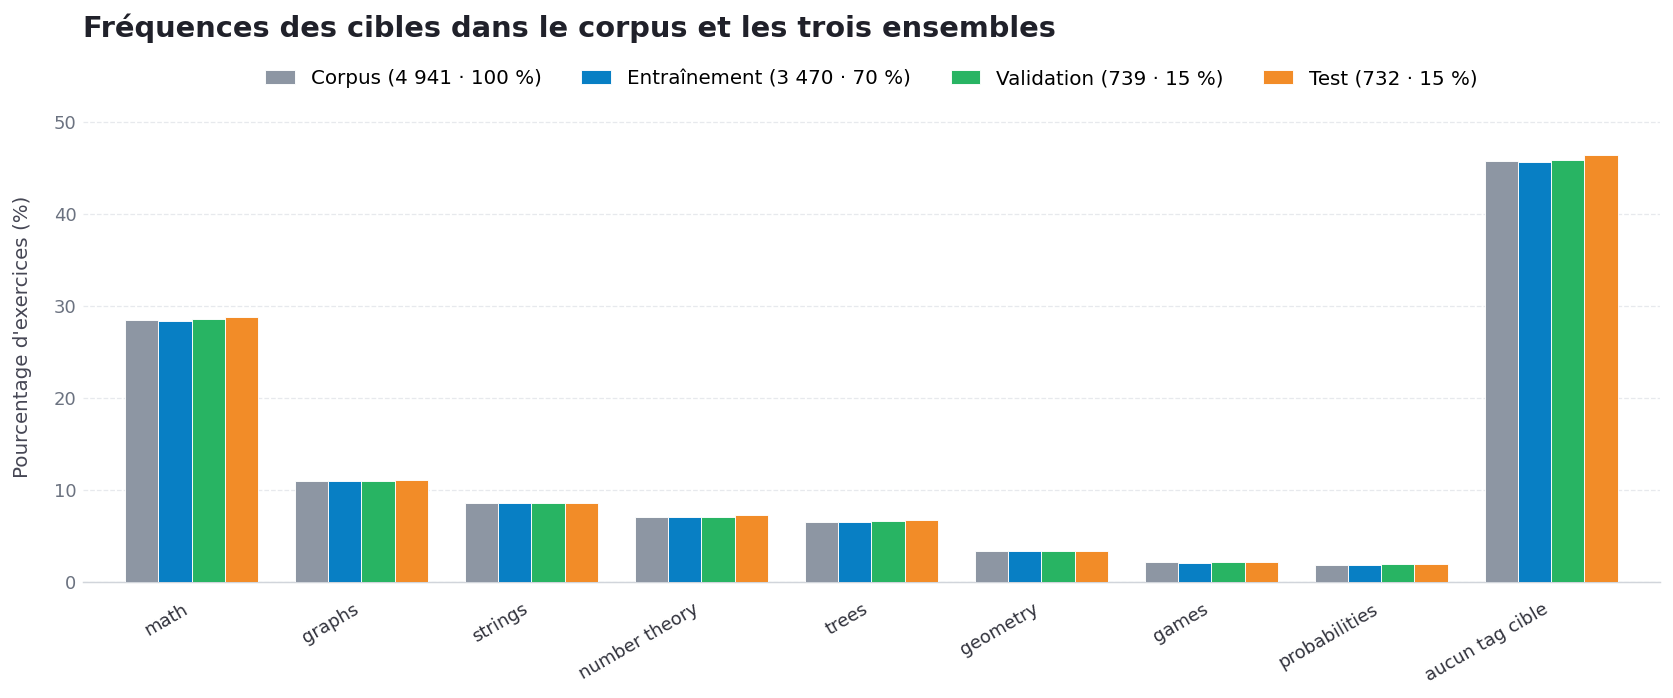

In [6]:
colors = ["#8D96A3", "#087FC4", "#28B463", "#F28C28"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

fig, ax = plt.subplots(figsize=(13, 5.5), dpi=130)
pourcentages.plot.bar(
    ax=ax, width=0.78, color=colors,
    edgecolor="white", linewidth=0.5, zorder=3
)

ax.set_title(
    "Fréquences des cibles dans le corpus et les trois ensembles",
    loc="left", pad=30, color="#20212A"
)
ax.set_xlabel("")
ax.set_ylabel("Pourcentage d'exercices (%)", labelpad=12, color="#454654")
ax.tick_params(axis="x", rotation=30, length=0, pad=10)
ax.tick_params(axis="y", length=0, colors="#6B7280")
plt.setp(ax.get_xticklabels(), ha="right", color="#30313B")

ax.set_axisbelow(True)
ax.yaxis.set_major_locator(MultipleLocator(10))
ax.grid(axis="y", linestyle="--", linewidth=0.7, color="#E5E7EB", alpha=0.9)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color("#D1D5DB")
ax.spines["bottom"].set_linewidth(0.8)
ax.set_ylim(0, pourcentages.max().max() * 1.15)

ax.legend(
    ["Corpus (4 941 · 100 %)", "Entraînement (3 470 · 70 %)",
     "Validation (739 · 15 %)", "Test (732 · 15 %)"],
    loc="upper center", bbox_to_anchor=(0.5, 1.08),
    ncol=4, frameon=False, fontsize=11,
    columnspacing=2, handlelength=1.5
)

plt.tight_layout()
plt.show()

## 6. Enregistrer les cinq fichiers préparés

Les trois JSONL contiennent uniquement `fichier_source`, `prob_desc_description`, `prob_desc_notes`, `prob_desc_output_spec`, `prob_desc_input_spec`, `source_code`, `src_uid`, `code_uid`, `tags` et les huit colonnes `cible_…`. 

| Fichier dans `data/` | Rôle |
| --- | --- |
| `entrainement.jsonl` | Données pour apprendre les représentations et le modèle |
| `validation.jsonl` | Données pour choisir les réglages et les seuils |
| `test.jsonl` | Données réservées à l’évaluation finale |
| `partitions.csv` | Identifiants, fichiers sources et affectation de chaque exercice |
| `exclusions.csv` | Identifiants des exercices exclus en raison d'une liste de tags vide |

Les fichiers sont d’abord écrits et vérifiés dans un dossier temporaire, puis remplacent les cinq fichiers de préparation. Les paramètres et contrôles de reproductibilité restent dans le notebook.

In [7]:
def lire_jsonl(chemin):
    with chemin.open(encoding="utf-8") as fichier:
        return [json.loads(ligne) for ligne in fichier]

assert [f.name for f in sorted(dossier_brut.glob("*.json"))] == [f.name for f in fichiers]
assert calculer_empreinte(fichiers) == empreinte_source

dossier_data.mkdir(exist_ok=True)
with tempfile.TemporaryDirectory(prefix=".preparation_", dir=dossier_data) as temporaire:
    dossier_temporaire = Path(temporaire)
    for nom, positions in indices.items():
        chemin = dossier_temporaire / f"{nom}.jsonl"
        with chemin.open("w", encoding="utf-8", newline="\n") as fichier:
            for position in positions:
                fichier.write(json.dumps(enregistrements[int(position)], ensure_ascii=False, allow_nan=False) + "\n")
        assert lire_jsonl(chemin) == [enregistrements[int(position)] for position in positions]
    affectations.to_csv(dossier_temporaire / "partitions.csv", index=False, encoding="utf-8", lineterminator="\n")
    exclusions.to_csv(dossier_temporaire / "exclusions.csv", index=False, encoding="utf-8", lineterminator="\n")
    empreintes_exports = {chemin.name: hashlib.sha256(chemin.read_bytes()).hexdigest()
                         for chemin in sorted(dossier_temporaire.iterdir())}
    for nom in empreintes_exports:
        os.replace(dossier_temporaire / nom, dossier_data / nom)

(dossier_data / "metadonnees.json").unlink(missing_ok=True)
print("Les cinq fichiers de préparation ont été enregistrés dans data/.")

Les cinq fichiers de préparation ont été enregistrés dans data/.


## 7. Relire et valider les fichiers produits

Recharger les données réellement enregistrées et vérifier les contenus, les cibles, les affectations et les empreintes. Les futures expériences devront réutiliser ces partitions.

In [8]:
for nom, empreinte in empreintes_exports.items():
    assert hashlib.sha256((dossier_data / nom).read_bytes()).hexdigest() == empreinte

identifiants_relus = []
for nom, positions in indices.items():
    exercices_relus = lire_jsonl(dossier_data / f"{nom}.jsonl")
    assert exercices_relus == [enregistrements[int(position)] for position in positions]
    assert all(list(exercice) == champs_exportes for exercice in exercices_relus)
    assert all(type(exercice[colonne]) is int and exercice[colonne] in [0, 1]
               for exercice in exercices_relus for colonne in colonnes_cibles)
    identifiants_relus.extend(exercice["src_uid"] for exercice in exercices_relus)
assert len(identifiants_relus) == len(set(identifiants_relus)) == len(donnees)
assert set(identifiants_relus) == set(donnees["src_uid"])

for nom, tableau in [("partitions", affectations), ("exclusions", exclusions)]:
    relu = pd.read_csv(dossier_data / f"{nom}.csv", dtype=str, keep_default_na=False)
    pd.testing.assert_frame_equal(relu, tableau.reset_index(drop=True).astype(str), check_dtype=False)
assert calculer_empreinte(fichiers) == empreinte_source
print("Vérifications réussies.")

Vérifications réussies.
